In [1]:
import os
import pydicom
import SimpleITK as sitk
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import nibabel as nib

In [2]:
hgucegxi_dir=r"Dataset\DICOMs\HGUCEGXI"
files = os.listdir(hgucegxi_dir)
files[:5]

['I1000000', 'I1000001', 'I1010000', 'I1020000', 'I1030000']

In [3]:
# convert entire dicom series to nifti including metadata
def convert_to_nifti(dicom_dir, nifti_dir):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dicom_dir)
    reader.SetFileNames(dicom_names)
    image = reader.Execute()
    sitk.WriteImage(image, nifti_dir)
    
convert_to_nifti(hgucegxi_dir, r"Dataset\NIFTIs\HGUCEGXI.nii")

In [34]:
# load nifti file
nifti = nib.load(r"Dataset\NIFTIs\HGUCEGXI.nii")

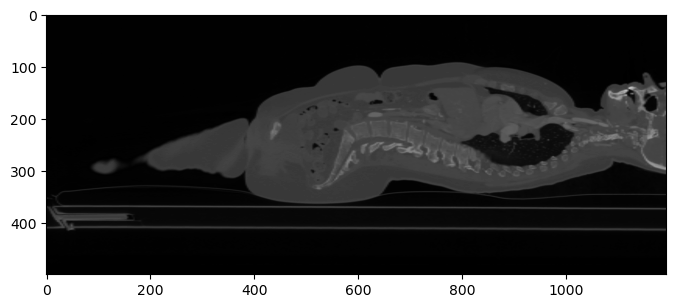

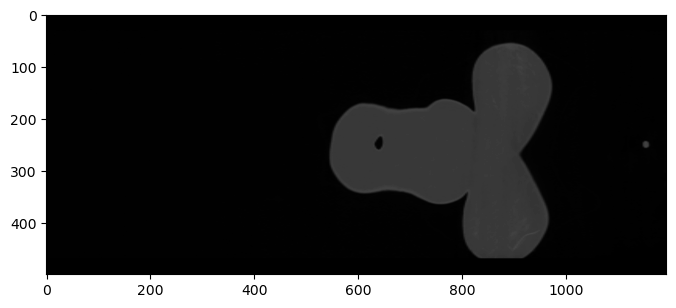

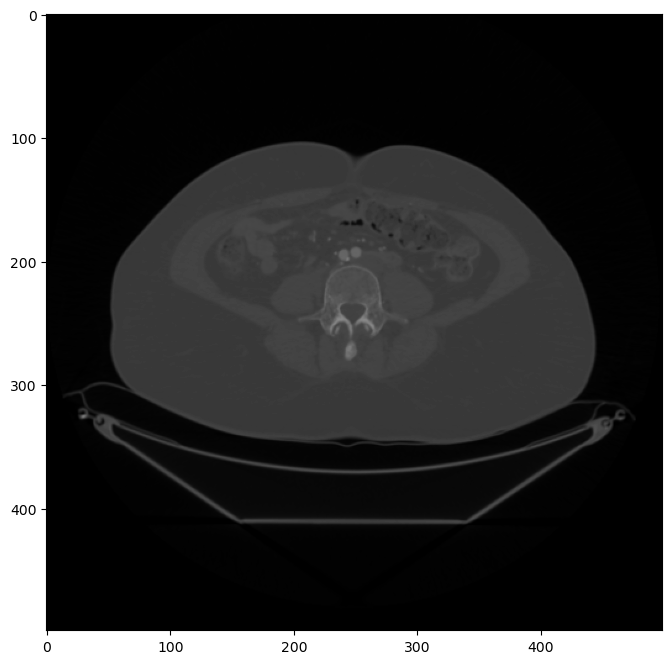

In [232]:
def get_slices(image_3d, x, y, z):
    spacing = (np.array(nifti.header.get_zooms())*image_3d.shape).astype(int)
    
    x_img = cv2.resize(image_3d[x, :, :], spacing[:0:-1])
    y_img = cv2.resize(image_3d[:, y, :], spacing[::-2])
    z_img = cv2.resize(cv2.rotate(image_3d[:, :, z], cv2.ROTATE_90_CLOCKWISE), spacing[:2])
    return x_img, y_img, z_img

img_slices=get_slices(nifti.get_fdata(), 250, 115, 215)

plt.figure(figsize=(8, 5))
plt.imshow(img_slices[0], cmap='gray', vmin=-1024, vmax=3071)

plt.show()
plt.figure(figsize=(8, 5))
plt.imshow(img_slices[1], cmap='gray', vmin=-1024, vmax=3071)
plt.show()
plt.figure(figsize=(8, 8))
plt.imshow(img_slices[2], cmap='gray', vmin=-1024, vmax=3071)
plt.show()

In [230]:
image_3d=np.array(nifti.get_fdata())
blood_hu=(image_3d>25) & (image_3d<50)
blood_contr_hu=(image_3d>90) & (image_3d<310)
tissue_hu = (image_3d>-200) & (image_3d<200)

roi = np.zeros_like(image_3d)
roi[:, 80:200, 130:220]=1

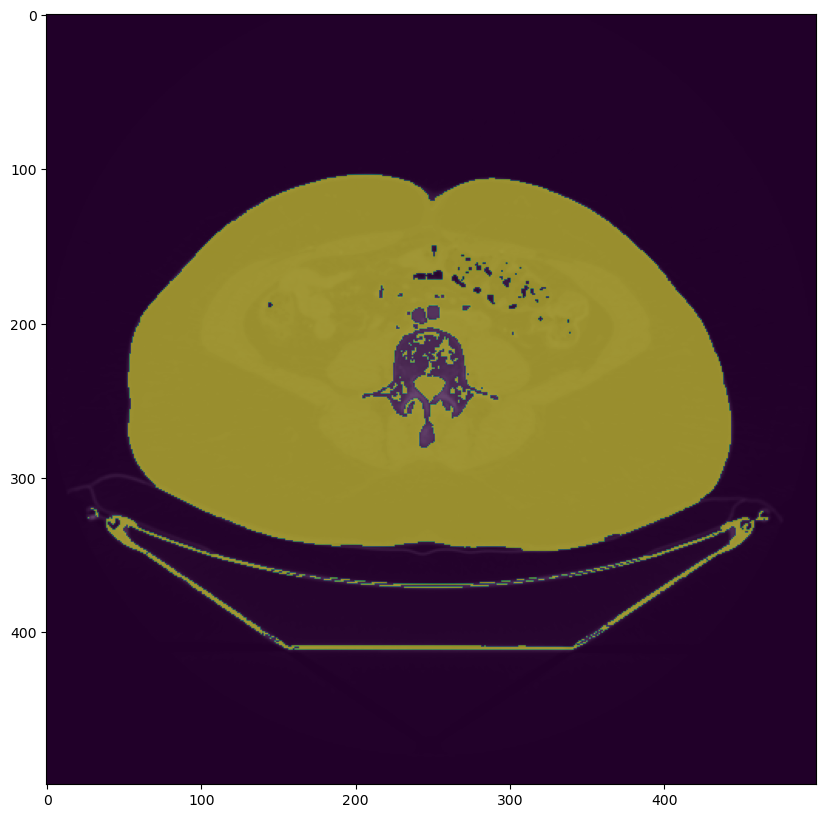

In [251]:
plt.figure(figsize=(15, 10))
plt.imshow(get_slices(nifti.get_fdata(), 250, 115, 215)[2], cmap='gray', vmin=-1024, vmax=3071)
plt.imshow(get_slices(tissue_hu.astype(np.uint8), 250, 115, 215)[2], alpha=0.5)

In [401]:
import itertools
from collections import deque

def region_growing(image, seed, threshold):
    image = image.copy()
    seed=tuple(seed)
    stack = deque([seed])
    shaper=np.array(image.shape)
    
    visited = np.zeros_like(image, dtype=bool)
    mask = np.zeros_like(image)

    while stack:
        pos = stack.pop()
        
        if visited[pos]: continue
        visited[pos] = True

        if abs(image[pos] - image[seed]) < threshold:
            mask[pos] = 1
            
            pos=np.array(pos)
            temp = [
                pos + np.array(indices)
                for indices in itertools.product(range(-1, 2), repeat=len(pos))
            ]
            stack.extend([
                tuple(a) for a in temp 
                    if a.min() >= 0 
                       and all(a < shaper) 
                       and not visited[*a]
            ])

    return mask

region_growing(image_3d[0], (250, 115), 60)

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       ...,
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]])

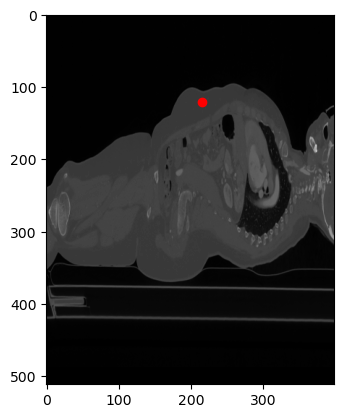

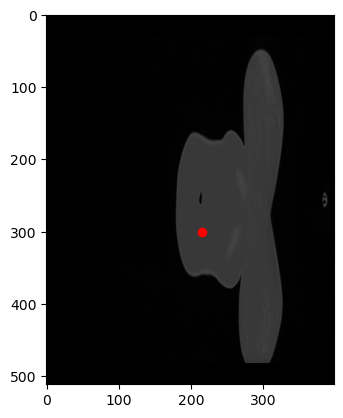

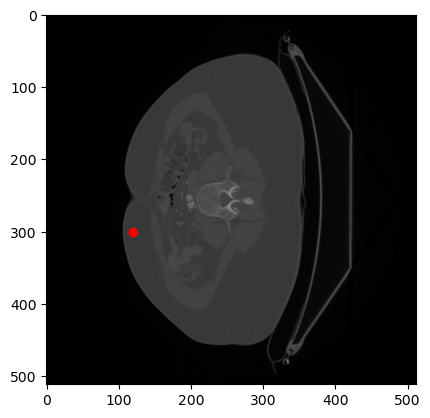

In [340]:
seed = (300, 120, 215)

plt.imshow(image_3d[seed[0],:,:], cmap='gray', vmin=-1024, vmax=3071)
plt.scatter(seed[2], seed[1], c='r')
plt.show()

plt.imshow(image_3d[:,seed[1],:], cmap='gray', vmin=-1024, vmax=3071)
plt.scatter(seed[2], seed[0], c='r')
plt.show()

plt.imshow(image_3d[:,:,seed[2]], cmap='gray', vmin=-1024, vmax=3071)
plt.scatter(seed[1], seed[0], c='r')
plt.show()


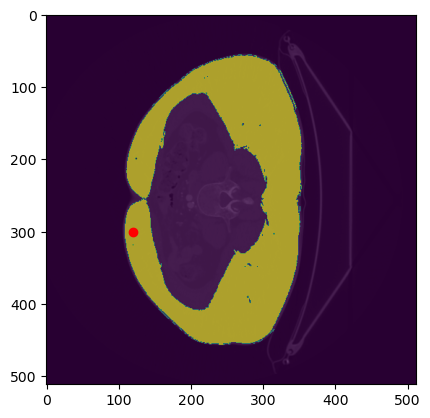

In [402]:
plt.imshow(image_3d[:,:,seed[2]], cmap='gray', vmin=-1024, vmax=3071)
plt.imshow(region_growing(image_3d[:,:,seed[2]], seed[:-1], 60), alpha=0.6)
plt.scatter(seed[1], seed[0], c='r')
plt.show()

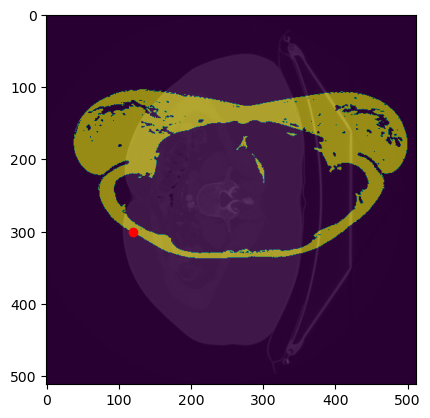

In [439]:
plt.imshow(image_3d[:,:,seed[2]], cmap='gray', vmin=-1024, vmax=3071)
plt.imshow(temp[:,:,seed[2]+100], alpha=0.6)
plt.scatter(seed[1], seed[0], c='r')
plt.show()

In [419]:
import matplotlib.pyplot as plt
import SimpleITK as sitk

def myshow(img, title=None, margin=0.05, dpi=80):
    nda = sitk.GetArrayFromImage(img)
    spacing = img.GetSpacing()

    if nda.ndim == 3:
        # fastest dim, either component or x
        c = nda.shape[-1]

        # the the number of components is 3 or 4 consider it an RGB image
        if c not in (3,4):
            nda = nda[nda.shape[0]//2,:,:]

    elif nda.ndim == 4:
        c = nda.shape[-1]

        if c not in (3,4):
            raise RuntimeError("Unable to show 3D-vector Image")

        # take a z-slice
        nda = nda[nda.shape[0]//2,:,:,:]

    ysize = nda.shape[0]
    xsize = nda.shape[1]

    # Make a figure big enough to accommodate an axis of xpixels by ypixels
    # as well as the ticklabels, etc...
    figsize = (1 + margin) * ysize / dpi, (1 + margin) * xsize / dpi

    fig = plt.figure(figsize=figsize, dpi=dpi)
    # Make the axis the right size...
    ax = fig.add_axes([margin, margin, 1 - 2*margin, 1 - 2*margin])

    extent = (0, xsize*spacing[1], ysize*spacing[0], 0)

    t = ax.imshow(nda, extent=extent, interpolation=None)

    if nda.ndim == 2:
        t.set_cmap("gray")

    if title:
        plt.title(title)

    plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


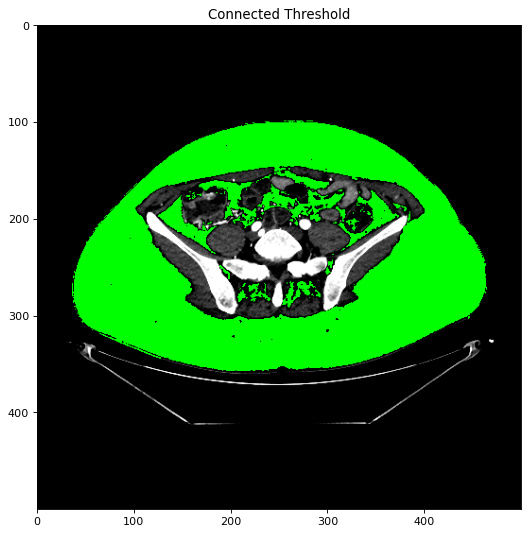

In [434]:
# import SimpleITK as sitk
# 
# # Assuming 'image' is your 3D MRI image and 'seed' is the seed point for region growing
# image = sitk.ReadImage(r'Dataset\NIFTIs\HGUCEGXI.nii')
# seed = (300, 120, 215)
# lower = image_3d[*seed]-60
# upper = image_3d[*seed]+60
# 
# # Perform region growing
# seg = sitk.Image(image.GetSize(), sitk.sitkUInt8)
# seg.CopyInformation(image)
# seg[seed] = 1
# seg = sitk.BinaryDilate(seg, [3, 3, 3])
# myshow(sitk.LabelOverlay(image, seg), "Initial Seed")

seg_con = sitk.ConnectedThreshold(image, seedList=[seed], lower=lower, upper=upper)

myshow(sitk.LabelOverlay(image, seg_con), "Connected Threshold")

In [436]:
temp=np.array(sitk.GetArrayFromImage(seg_con)).transpose(1,2,0)